# Direct Spherical Context Encoder–Decoder

教授方案：

\[
x_{\text{context}}\rightarrow z_{\text{spherical}}\rightarrow\hat y_{\text{center word}}
\]

不使用预训练 Word2Vec。输入是上下文，输出是中心词，因此这是 **encoder–decoder with a spherical bottleneck**，不是传统 autoencoder。

`nn.EmbeddingBag` 等价于对 context multi-hot vector 做线性变换 \(Wx_{\text{context}}\)，但无需显式构造30,000维稠密向量。该矩阵从零开始训练，并不是外部 Word2Vec。


In [7]:
import random, urllib.request, zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display


In [8]:
SEED = 42
VOCAB_SIZE = 30_000
WINDOW_RADIUS = 5
MIN_COUNT = 5
BATCH_SIZE = 256
EPOCHS = 50
LEARNING_RATE = 2e-3
CONTEXT_HIDDEN_DIM = 256
ENCODER_HIDDEN_DIM = 128
LATENT_DIM = 32
SAMPLE_ALPHA = 0.15
BETA_RIESZ = 1e-3
RIESZ_SUBSAMPLE = 256
MAX_TOKENS = 3_000_000

DATA_DIR = Path("./data")
TEXT8_PATH = DATA_DIR / "text8"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)


Device: cuda


## 1. Load text8


In [9]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not TEXT8_PATH.exists():
    zip_path = DATA_DIR / "text8.zip"
    urllib.request.urlretrieve(
        "http://mattmahoney.net/dc/text8.zip",
        zip_path,
    )
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA_DIR)

tokens = TEXT8_PATH.read_text(
    encoding="utf-8"
).split()

if MAX_TOKENS is not None:
    tokens = tokens[:MAX_TOKENS]

print("Tokens:", len(tokens))


Tokens: 3000000


## 2. Vocabulary


In [10]:
counter = Counter(tokens)

words = [
    word
    for word, count in counter.most_common(VOCAB_SIZE - 2)
    if count >= MIN_COUNT
]

idx_to_word = ["<pad>", "<unk>"] + words
word_to_idx = {
    word: index
    for index, word in enumerate(idx_to_word)
}

PAD_ID = word_to_idx["<pad>"]
UNK_ID = word_to_idx["<unk>"]

encoded_tokens = np.asarray(
    [word_to_idx.get(word, UNK_ID) for word in tokens],
    dtype=np.int64,
)

ACTUAL_VOCAB_SIZE = len(idx_to_word)

print("Vocabulary size:", ACTUAL_VOCAB_SIZE)
print("UNK ratio:", float(np.mean(encoded_tokens == UNK_ID)))


Vocabulary size: 27323
UNK ratio: 0.036664


## 3. Context → center word dataset

窗口半径为5：

```text
5 left words + center word + 5 right words
```

模型输入10个上下文词，输出中心词。


In [11]:
class ContextCenterDataset(Dataset):
    def __init__(self, token_ids, window_radius=5):
        self.token_ids = token_ids
        self.window_radius = int(window_radius)

    def __len__(self):
        return len(self.token_ids) - 2 * self.window_radius

    def __getitem__(self, index):
        center_position = index + self.window_radius

        left = self.token_ids[
            center_position - self.window_radius:
            center_position
        ]

        right = self.token_ids[
            center_position + 1:
            center_position + self.window_radius + 1
        ]

        context = np.concatenate([left, right])
        center = self.token_ids[center_position]

        return (
            torch.tensor(context, dtype=torch.long),
            torch.tensor(center, dtype=torch.long),
        )


split = int(0.90 * len(encoded_tokens))

train_dataset = ContextCenterDataset(
    encoded_tokens[:split],
    WINDOW_RADIUS,
)

valid_dataset = ContextCenterDataset(
    encoded_tokens[split - 2 * WINDOW_RADIUS:],
    WINDOW_RADIUS,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Train:", len(train_dataset))
print("Validation:", len(valid_dataset))


Train: 2699990
Validation: 300000


## 4. Direct spherical model


In [12]:
def riesz_energy(points, subsample=256, s=1.0):
    if points.size(0) < 2:
        return torch.zeros(
            (),
            device=points.device,
            dtype=points.dtype,
        )

    if subsample is not None and points.size(0) > subsample:
        indices = torch.randperm(
            points.size(0),
            device=points.device,
        )[:subsample]
        points = points[indices]

    distances = torch.cdist(points, points)

    mask = torch.triu(
        torch.ones_like(distances, dtype=torch.bool),
        diagonal=1,
    )

    valid = distances[mask]

    return torch.mean(
        1.0 / torch.clamp(valid, min=1e-4).pow(s)
    )


class DirectSphericalContextModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        context_hidden_dim=256,
        encoder_hidden_dim=128,
        latent_dim=32,
        sample_alpha=0.15,
    ):
        super().__init__()

        self.sample_alpha = float(sample_alpha)

        self.context_projection = nn.EmbeddingBag(
            vocab_size,
            context_hidden_dim,
            mode="sum",
        )

        self.encoder = nn.Sequential(
            nn.Linear(context_hidden_dim, encoder_hidden_dim),
            nn.ReLU(),
            nn.Linear(encoder_hidden_dim, latent_dim),
        )

        self.decoder = nn.Linear(
            latent_dim,
            vocab_size,
        )

    def encode_context(self, context_ids):
        batch_size, context_length = context_ids.shape

        flattened = context_ids.reshape(-1)

        offsets = torch.arange(
            0,
            batch_size * context_length,
            context_length,
            device=context_ids.device,
        )

        context_hidden = self.context_projection(
            flattened,
            offsets,
        )

        raw_direction = self.encoder(context_hidden)

        return F.normalize(
            raw_direction,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def sample_on_sphere(self, mean_direction):
        ambient_noise = torch.randn_like(mean_direction)

        tangent_noise = (
            ambient_noise
            - (
                ambient_noise * mean_direction
            ).sum(dim=-1, keepdim=True)
            * mean_direction
        )

        tangent_noise = F.normalize(
            tangent_noise,
            p=2,
            dim=-1,
            eps=1e-8,
        )

        theta = self.sample_alpha * torch.rand(
            mean_direction.size(0),
            1,
            device=mean_direction.device,
        )

        z = (
            mean_direction * torch.cos(theta)
            + tangent_noise * torch.sin(theta)
        )

        return F.normalize(
            z,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def forward(self, context_ids, sample=True):
        mean_direction = self.encode_context(context_ids)

        z = (
            self.sample_on_sphere(mean_direction)
            if sample
            else mean_direction
        )

        logits = self.decoder(z)

        return {
            "logits": logits,
            "mean_direction": mean_direction,
            "z": z,
        }


model = DirectSphericalContextModel(
    vocab_size=ACTUAL_VOCAB_SIZE,
    context_hidden_dim=CONTEXT_HIDDEN_DIM,
    encoder_hidden_dim=ENCODER_HIDDEN_DIM,
    latent_dim=LATENT_DIM,
    sample_alpha=SAMPLE_ALPHA,
).to(DEVICE)

print(model)


DirectSphericalContextModel(
  (context_projection): EmbeddingBag(27323, 256, mode='sum')
  (encoder): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Linear(in_features=32, out_features=27323, bias=True)
)


## 5. Loss

\[
\mathcal L =
\mathcal L_{\text{center-word classification}}
+
\beta\mathcal L_{\text{Riesz}}
\]


In [13]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []

for epoch in range(EPOCHS):
    model.train()

    totals = defaultdict(float)
    steps = 0

    for context_ids, center_ids in train_loader:
        context_ids = context_ids.to(
            DEVICE,
            non_blocking=True,
        )

        center_ids = center_ids.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(set_to_none=True)

        output = model(
            context_ids,
            sample=True,
        )

        center_loss = F.cross_entropy(
            output["logits"],
            center_ids,
        )

        riesz_loss = riesz_energy(
            output["mean_direction"],
            subsample=RIESZ_SUBSAMPLE,
        )

        loss = (
            center_loss
            + BETA_RIESZ * riesz_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0,
        )

        optimizer.step()

        top1 = (
            output["logits"]
            .argmax(dim=-1)
            .eq(center_ids)
            .float()
            .mean()
        )

        totals["loss"] += float(loss.detach().cpu())
        totals["center"] += float(center_loss.detach().cpu())
        totals["riesz"] += float(riesz_loss.detach().cpu())
        totals["top1"] += float(top1.detach().cpu())
        steps += 1

    row = {
        "epoch": epoch + 1,
        "loss": totals["loss"] / steps,
        "center_loss": totals["center"] / steps,
        "riesz": totals["riesz"] / steps,
        "train_top1": totals["top1"] / steps,
    }

    history.append(row)
    print(row)

history = pd.DataFrame(history)
display(history)


{'epoch': 1, 'loss': 6.68824777994674, 'center_loss': 6.6868586338582485, 'riesz': 1.3891459440375726, 'train_top1': 0.10827855055093358}
{'epoch': 2, 'loss': 6.267482053954375, 'center_loss': 6.266685772385204, 'riesz': 0.7962831495677825, 'train_top1': 0.13200728974390835}
{'epoch': 3, 'loss': 6.068026468834516, 'center_loss': 6.067266074381609, 'riesz': 0.760393303492018, 'train_top1': 0.14354395121265343}
{'epoch': 4, 'loss': 5.922989739075966, 'center_loss': 5.922245093767277, 'riesz': 0.7446442670230787, 'train_top1': 0.1518020014876131}
{'epoch': 5, 'loss': 5.805171401825993, 'center_loss': 5.80443529627431, 'riesz': 0.7361040534798631, 'train_top1': 0.1590259172551449}
{'epoch': 6, 'loss': 5.7052321872564695, 'center_loss': 5.704501178125143, 'riesz': 0.7310094119440699, 'train_top1': 0.16563974679607096}
{'epoch': 7, 'loss': 5.617873308974397, 'center_loss': 5.617144951404887, 'riesz': 0.7283574561377866, 'train_top1': 0.17189013654500532}
{'epoch': 8, 'loss': 5.54050996471516

,epoch,loss,center_loss,riesz,train_top1
0,1,6.688248,6.686859,1.389146,0.108279
1,2,6.267482,6.266686,0.796283,0.132007
2,3,6.068026,6.067266,0.760393,0.143544
3,4,5.922990,5.922245,0.744644,0.151802
4,5,5.805171,5.804435,0.736104,0.159026
5,6,5.705232,5.704501,0.731009,0.165640
6,7,5.617873,5.617145,0.728357,0.171890
7,8,5.540510,5.539783,0.726748,0.177676
8,9,5.470666,5.469940,0.726139,0.182933
9,10,5.407044,5.406318,0.726028,0.188147


## 6. Validation


In [14]:
def evaluate_model(model, loader):
    model.eval()

    totals = defaultdict(float)
    steps = 0

    with torch.no_grad():
        for context_ids, center_ids in loader:
            context_ids = context_ids.to(DEVICE)
            center_ids = center_ids.to(DEVICE)

            output = model(
                context_ids,
                sample=False,
            )

            loss = F.cross_entropy(
                output["logits"],
                center_ids,
            )

            top5 = torch.topk(
                output["logits"],
                k=5,
                dim=-1,
            ).indices

            totals["loss"] += float(loss.cpu())

            totals["top1"] += float(
                top5[:, 0]
                .eq(center_ids)
                .float()
                .mean()
                .cpu()
            )

            totals["top5"] += float(
                top5
                .eq(center_ids.unsqueeze(1))
                .any(dim=1)
                .float()
                .mean()
                .cpu()
            )

            totals["latent_norm"] += float(
                output["z"]
                .norm(dim=-1)
                .mean()
                .cpu()
            )

            steps += 1

    return {
        key: value / steps
        for key, value in totals.items()
    }


display(
    pd.DataFrame([
        evaluate_model(model, valid_loader)
    ])
)


,loss,top1,top5,latent_norm
0,7.486697,0.091826,0.209036,1.0


## 7. Inspect predictions


In [15]:
model.eval()

context_batch, center_batch = next(
    iter(valid_loader)
)

context_batch = context_batch[:12].to(DEVICE)
center_batch = center_batch[:12].to(DEVICE)

with torch.no_grad():
    output = model(
        context_batch,
        sample=False,
    )

    top5_ids = torch.topk(
        output["logits"],
        k=5,
        dim=-1,
    ).indices.cpu().numpy()

rows = []

for index in range(len(context_batch)):
    rows.append({
        "context": " ".join(
            idx_to_word[token_id]
            for token_id in context_batch[index].cpu().numpy()
        ),
        "target": idx_to_word[
            int(center_batch[index].cpu())
        ],
        "top5_predictions": [
            idx_to_word[token_id]
            for token_id in top5_ids[index]
        ],
    })

display(pd.DataFrame(rows))


,context,target,top5_predictions
0,the well informed is <unk> as an inspiration o...,offered,"[as, <unk>, art, writer, character]"
1,well informed is <unk> offered an inspiration ...,as,"[as, that, also, which, best]"
2,informed is <unk> offered as inspiration of th...,an,"[also, to, as, many, for]"
3,is <unk> offered as an of the baroque which ap...,inspiration,"[<unk>, variety, style, art, character]"
4,<unk> offered as an inspiration the baroque wh...,of,"[<unk>, new, was, him, greek]"
5,offered as an inspiration of baroque which app...,the,"[<unk>, the, variety, piece, was]"
6,as an inspiration of the which appeared howeve...,baroque,"[new, between, <unk>, was, story]"
7,an inspiration of the baroque appeared however...,which,"[new, period, style, <unk>, as]"
8,inspiration of the baroque which however a gen...,appeared,"[was, became, period, made, continued]"
9,of the baroque which appeared a generation lat...,however,"[in, on, with, at, was]"


## 8. Build word-level spherical representations

这里有一个重要区别：模型原始 latent 表示的是一个**上下文窗口**，不是单独的词。

为了得到每个词的球面表示，我们聚合“该词作为中心词时”的所有 context latent：

\[
e_w =
\operatorname{normalize}
\left(
\sum_{i:y_i=w}z_i
\right)
\]


In [16]:
def build_word_spherical_embeddings(
    model,
    loader,
    vocab_size,
    max_batches=None,
):
    model.eval()

    sums = np.zeros(
        (vocab_size, LATENT_DIM),
        dtype=np.float64,
    )

    counts = np.zeros(
        vocab_size,
        dtype=np.int64,
    )

    with torch.no_grad():
        for batch_index, (
            context_ids,
            center_ids,
        ) in enumerate(loader):
            if (
                max_batches is not None
                and batch_index >= max_batches
            ):
                break

            output = model(
                context_ids.to(DEVICE),
                sample=False,
            )

            latents = output["z"].cpu().numpy()
            centers = center_ids.numpy()

            for word_id in np.unique(centers):
                mask = centers == word_id
                sums[word_id] += latents[mask].sum(axis=0)
                counts[word_id] += int(mask.sum())

    embeddings = np.zeros_like(sums)
    valid = counts > 0

    norms = np.linalg.norm(
        sums[valid],
        axis=1,
        keepdims=True,
    )

    embeddings[valid] = (
        sums[valid]
        / np.clip(norms, 1e-12, None)
    )

    return embeddings, counts


word_spherical_embeddings, word_context_counts = (
    build_word_spherical_embeddings(
        model,
        train_loader,
        ACTUAL_VOCAB_SIZE,
    )
)

print(
    "Words represented:",
    int(np.sum(word_context_counts > 0)),
)


Words represented: 27181


## 9. Nearest neighbors


In [17]:
def nearest_words(query_word, top_k=10):
    if query_word not in word_to_idx:
        raise KeyError(query_word)

    query_id = word_to_idx[query_word]
    query = word_spherical_embeddings[query_id]

    if np.linalg.norm(query) < 1e-12:
        raise ValueError("No representation for this word.")

    similarities = (
        word_spherical_embeddings @ query
    )

    similarities[word_context_counts == 0] = -np.inf
    similarities[query_id] = -np.inf

    nearest_ids = np.argsort(
        -similarities
    )[:top_k]

    return pd.DataFrame({
        "word": [
            idx_to_word[index]
            for index in nearest_ids
        ],
        "cosine_similarity": similarities[nearest_ids],
        "context_count": word_context_counts[nearest_ids],
    })


for query_word in [
    "king",
    "queen",
    "france",
    "italy",
    "man",
    "woman",
]:
    if query_word in word_to_idx:
        print("Query:", query_word)
        display(
            nearest_words(
                query_word,
                top_k=10,
            )
        )


Query: king


,word,cosine_similarity,context_count
0,prince,0.893793,245
1,regent,0.888737,29
2,emperor,0.879003,535
3,grandson,0.878657,41
4,macedon,0.856865,53
5,queen,0.844880,286
6,son,0.844073,775
7,ruler,0.841181,114
8,empress,0.836727,24
9,sancho,0.829213,16


Query: queen


,word,cosine_similarity,context_count
0,lord,0.853423,344
1,king,0.844880,1304
2,consort,0.824991,14
3,prince,0.814062,245
4,bishop,0.797012,191
5,princess,0.793187,99
6,theresa,0.791983,7
7,bentinck,0.786843,5
8,lady,0.776479,68
9,toulouse,0.773817,28


Query: france


...

,word,cosine_similarity,context_count
0,france,0.903965,637
1,spain,0.897890,294
2,switzerland,0.882866,96
3,germany,0.882749,706
4,india,0.867642,447
5,prussia,0.863410,71
6,persia,0.862374,88
7,russia,0.856913,388
8,hungary,0.856630,154
9,thrace,0.856575,32


Query: man


,word,cosine_similarity,context_count
0,woman,0.916690,264
1,evil,0.860726,153
2,passion,0.857415,67
3,hero,0.850737,120
4,dream,0.849514,69
5,love,0.835266,363
6,forehead,0.832811,10
7,child,0.819378,226
8,sacrifice,0.812128,81
9,carefree,0.809947,6


Query: woman


,word,cosine_similarity,context_count
0,man,0.916690,959
1,child,0.876790,226
2,herself,0.816417,93
3,dione,0.800072,5
4,sacrifice,0.796507,81
5,girl,0.793964,109
6,curse,0.788774,27
7,hero,0.784618,120
8,villain,0.782311,13
9,wise,0.781710,47


## 10. Save model and embeddings


In [18]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "word_to_idx": word_to_idx,
        "idx_to_word": idx_to_word,
    },
    "direct_spherical_context_model.pt",
)

np.savez_compressed(
    "direct_spherical_word_embeddings.npz",
    embeddings=word_spherical_embeddings,
    counts=word_context_counts,
    words=np.asarray(
        idx_to_word,
        dtype=object,
    ),
)

print("Saved.")


Saved.


## 结论

这个版本实现了教授讨论的直接方案：

- 不使用预训练 Word2Vec；
- 直接从上下文得到球面 latent；
- decoder/classifier 根据 latent 预测中心词；
- 之后通过聚合 context latent，得到可用于关系测试和球面 transport 的 word-level spherical representations。


## 11. Semantic relation transfer on the sphere

这一部分加入之前使用过的 **relation extraction + parallel transport + Exp-map** 测试。

给定关系：

\[
a\rightarrow b
\]

先提取球面 relation tangent vector：

\[
v_{ab}=\log_a(b)
\]

然后把 relation 搬到新的起点 \(c\)：

\[
\tilde v_{ab}^{(c)} = PT_{a\rightarrow c}(v_{ab})
\]

最后：

\[
\hat d=\operatorname{Exp}_c(\tilde v_{ab}^{(c)})
\]

如果语义 relation 在 spherical latent space 中可以迁移，那么 \(\hat d\) 应该靠近预期 target \(d\)。

我们同时记录 relation angle、transport 前后 norm、target rank、Top-1/Top-5、endpoint 到 target 的角度距离以及 transported direction 和真实关系方向之间的夹角。


In [19]:
EPS_GEOM = 1e-8

def normalize_np(v):
    v = np.asarray(v, dtype=np.float64)
    norm = np.linalg.norm(v)
    if norm < EPS_GEOM:
        raise ValueError("Near-zero vector.")
    return v / norm

def spherical_distance_np(x, y):
    x = normalize_np(x)
    y = normalize_np(y)
    return float(np.arccos(np.clip(np.dot(x, y), -1.0, 1.0)))

def log_map_sphere(x, y):
    x = normalize_np(x)
    y = normalize_np(y)

    cosine = np.clip(np.dot(x, y), -1.0, 1.0)
    theta = np.arccos(cosine)

    if theta < EPS_GEOM:
        return np.zeros_like(x)

    direction = y - cosine * x
    direction_norm = np.linalg.norm(direction)

    if direction_norm < EPS_GEOM:
        return np.zeros_like(x)

    return theta * direction / direction_norm

def exp_map_sphere(x, tangent):
    x = normalize_np(x)
    tangent = np.asarray(tangent, dtype=np.float64)

    tangent = tangent - np.dot(tangent, x) * x
    tangent_norm = np.linalg.norm(tangent)

    if tangent_norm < EPS_GEOM:
        return x.copy()

    endpoint = (
        np.cos(tangent_norm) * x
        + np.sin(tangent_norm) * tangent / tangent_norm
    )

    return normalize_np(endpoint)

def parallel_transport_sphere(tangent, x, y):
    x = normalize_np(x)
    y = normalize_np(y)

    tangent = np.asarray(tangent, dtype=np.float64)
    tangent = tangent - np.dot(tangent, x) * x

    denominator = 1.0 + np.dot(x, y)

    if abs(denominator) < EPS_GEOM:
        raise ValueError(
            "Parallel transport is unstable for near-antipodal points."
        )

    transported = (
        tangent
        - (np.dot(tangent, y) / denominator) * (x + y)
    )

    transported = transported - np.dot(transported, y) * y
    return transported

def angle_between_vectors_deg(v1, v2):
    n1 = np.linalg.norm(v1)
    n2 = np.linalg.norm(v2)

    if n1 < EPS_GEOM or n2 < EPS_GEOM:
        return np.nan

    cosine = np.clip(
        np.dot(v1, v2) / (n1 * n2),
        -1.0,
        1.0,
    )

    return float(np.degrees(np.arccos(cosine)))


## 12. 使用 Direct Spherical Context Model 的 word representations

这里完全不使用 Word2Vec。

relation 直接从前面得到的：

```python
word_spherical_embeddings
```

中提取。因此测试的是：

> Direct context-based spherical representations 中，语义关系经过 parallel transport 后是否还能保留。


In [20]:
def get_word_latent(word):
    if word not in word_to_idx:
        raise KeyError(f"'{word}' is not in the vocabulary.")

    word_id = word_to_idx[word]

    if word_context_counts[word_id] <= 0:
        raise ValueError(f"'{word}' has no spherical representation.")

    return normalize_np(word_spherical_embeddings[word_id])

def nearest_words_to_vector(vector, top_k=10, exclude_words=None):
    vector = normalize_np(vector)

    similarities = word_spherical_embeddings @ vector
    similarities[word_context_counts == 0] = -np.inf

    if exclude_words is not None:
        for word in exclude_words:
            if word in word_to_idx:
                similarities[word_to_idx[word]] = -np.inf

    nearest_ids = np.argsort(-similarities)[:top_k]

    return pd.DataFrame({
        "rank": np.arange(1, len(nearest_ids) + 1),
        "word": [idx_to_word[i] for i in nearest_ids],
        "cosine_similarity": similarities[nearest_ids],
        "angle_deg": [
            float(np.degrees(np.arccos(np.clip(similarities[i], -1.0, 1.0))))
            for i in nearest_ids
        ],
    })

def rank_of_target(query_vector, target_word, exclude_words=None):
    query_vector = normalize_np(query_vector)
    similarities = word_spherical_embeddings @ query_vector

    similarities[word_context_counts == 0] = -np.inf

    if exclude_words is not None:
        for word in exclude_words:
            if word in word_to_idx and word != target_word:
                similarities[word_to_idx[word]] = -np.inf

    target_id = word_to_idx[target_word]
    target_similarity = similarities[target_id]

    rank = int(1 + np.sum(similarities > target_similarity))

    return rank, float(target_similarity)


## 13. Single relation transfer

对于四元组 \((a,b,c,d)\)，例如：

\[
(\text{man},\text{woman},\text{king},\text{queen})
\]

执行：

\[
v_{ab}=\log_a(b)
\]

\[
\tilde v = PT_{a\rightarrow c}(v_{ab})
\]

\[
\hat d = Exp_c(\tilde v)
\]

然后比较 \(\hat d\) 和真实 \(d\)。

特别关注：

- `original_relation_angle_deg`
- `transported_norm_error`
- `direction_error_deg`
- `distance_endpoint_to_target_deg`
- `distance_improvement_deg`
- `target_rank`
- `top1_correct`
- `top5_correct`


In [21]:
def test_relation_transport(a, b, c, d, top_k=10):
    for word in [a, b, c, d]:
        get_word_latent(word)

    z_a = get_word_latent(a)
    z_b = get_word_latent(b)
    z_c = get_word_latent(c)
    z_d = get_word_latent(d)

    v_ab = log_map_sphere(z_a, z_b)
    original_norm = np.linalg.norm(v_ab)

    if original_norm < EPS_GEOM:
        raise ValueError(f"Relation {a}->{b} has near-zero angle.")

    transported = parallel_transport_sphere(v_ab, z_a, z_c)
    transported_norm = np.linalg.norm(transported)

    endpoint = exp_map_sphere(z_c, transported)

    true_relation = log_map_sphere(z_c, z_d)
    true_relation_norm = np.linalg.norm(true_relation)

    target_distance = spherical_distance_np(endpoint, z_d)
    before_distance = spherical_distance_np(z_c, z_d)

    direction_error = angle_between_vectors_deg(
        transported,
        true_relation,
    )

    exclude = [a, b, c]

    neighbors = nearest_words_to_vector(
        endpoint,
        top_k=top_k,
        exclude_words=exclude,
    )

    target_rank, target_similarity = rank_of_target(
        endpoint,
        d,
        exclude_words=exclude,
    )

    summary = {
        "relation_source": f"{a}→{b}",
        "transfer_test": f"{c}→{d}",
        "original_relation_angle_deg": float(np.degrees(original_norm)),
        "true_target_relation_angle_deg": float(np.degrees(true_relation_norm)),
        "relation_length_difference_deg": float(
            np.degrees(abs(original_norm - true_relation_norm))
        ),
        "transported_norm_error": float(
            abs(transported_norm - original_norm)
        ),
        "direction_error_deg": float(direction_error),
        "distance_c_to_target_before_deg": float(np.degrees(before_distance)),
        "distance_endpoint_to_target_deg": float(np.degrees(target_distance)),
        "distance_improvement_deg": float(
            np.degrees(before_distance - target_distance)
        ),
        "target_rank": int(target_rank),
        "target_cosine_similarity": float(target_similarity),
        "top1_correct": bool(target_rank == 1),
        "top5_correct": bool(target_rank <= 5),
    }

    return {
        "summary": summary,
        "neighbors": neighbors,
        "endpoint": endpoint,
        "transported_vector": transported,
        "true_relation_vector": true_relation,
    }


## 14. 扩展 semantic relation 测试

这一版把 semantic transport 测试从原来的少量例子扩展为多个类别。

主要测试：

- **gender / family**
- **royalty**
- **country → capital**
- **capital → country**
- **country → nationality**
- **singular → plural**
- **comparative**
- **semantic category / hypernym-like relation**
- **geographic relation**

每个测试仍然执行：

\[
v_{ab}=\log_a(b)
\]

\[
\tilde v=PT_{a\rightarrow c}(v_{ab})
\]

\[
\hat d=Exp_c(\tilde v)
\]

然后检查 transported endpoint 是否仍然接近预期 target。

如果某个词不存在于当前 text8 vocabulary，会自动跳过，不会中断整个实验。


In [22]:
SEMANTIC_TRANSPORT_TESTS = [
    # ========================================================
    # Gender / family
    # ========================================================
    {
        "category": "gender_family",
        "a": "man", "b": "woman",
        "c": "king", "d": "queen",
    },
    {
        "category": "gender_family",
        "a": "king", "b": "queen",
        "c": "man", "d": "woman",
    },
    {
        "category": "gender_family",
        "a": "father", "b": "mother",
        "c": "son", "d": "daughter",
    },
    {
        "category": "gender_family",
        "a": "brother", "b": "sister",
        "c": "man", "d": "woman",
    },
    {
        "category": "gender_family",
        "a": "son", "b": "daughter",
        "c": "father", "d": "mother",
    },
    {
        "category": "gender_family",
        "a": "boy", "b": "girl",
        "c": "man", "d": "woman",
    },
    {
        "category": "gender_family",
        "a": "uncle", "b": "aunt",
        "c": "brother", "d": "sister",
    },

    # ========================================================
    # Royalty / social role
    # ========================================================
    {
        "category": "royalty",
        "a": "king", "b": "queen",
        "c": "prince", "d": "princess",
    },
    {
        "category": "royalty",
        "a": "prince", "b": "princess",
        "c": "king", "d": "queen",
    },

    # ========================================================
    # Country -> capital
    # ========================================================
    {
        "category": "country_to_capital",
        "a": "france", "b": "paris",
        "c": "italy", "d": "rome",
    },
    {
        "category": "country_to_capital",
        "a": "italy", "b": "rome",
        "c": "france", "d": "paris",
    },
    {
        "category": "country_to_capital",
        "a": "germany", "b": "berlin",
        "c": "france", "d": "paris",
    },
    {
        "category": "country_to_capital",
        "a": "france", "b": "paris",
        "c": "germany", "d": "berlin",
    },
    {
        "category": "country_to_capital",
        "a": "japan", "b": "tokyo",
        "c": "china", "d": "beijing",
    },
    {
        "category": "country_to_capital",
        "a": "china", "b": "beijing",
        "c": "japan", "d": "tokyo",
    },
    {
        "category": "country_to_capital",
        "a": "russia", "b": "moscow",
        "c": "england", "d": "london",
    },

    # ========================================================
    # Capital -> country
    # ========================================================
    {
        "category": "capital_to_country",
        "a": "paris", "b": "france",
        "c": "rome", "d": "italy",
    },
    {
        "category": "capital_to_country",
        "a": "berlin", "b": "germany",
        "c": "paris", "d": "france",
    },
    {
        "category": "capital_to_country",
        "a": "tokyo", "b": "japan",
        "c": "beijing", "d": "china",
    },

    # ========================================================
    # Country -> nationality / adjective
    # ========================================================
    {
        "category": "country_to_nationality",
        "a": "france", "b": "french",
        "c": "germany", "d": "german",
    },
    {
        "category": "country_to_nationality",
        "a": "germany", "b": "german",
        "c": "italy", "d": "italian",
    },
    {
        "category": "country_to_nationality",
        "a": "japan", "b": "japanese",
        "c": "china", "d": "chinese",
    },
    {
        "category": "country_to_nationality",
        "a": "china", "b": "chinese",
        "c": "japan", "d": "japanese",
    },
    {
        "category": "country_to_nationality",
        "a": "russia", "b": "russian",
        "c": "france", "d": "french",
    },

    # ========================================================
    # Singular -> plural
    # ========================================================
    {
        "category": "singular_to_plural",
        "a": "man", "b": "men",
        "c": "woman", "d": "women",
    },
    {
        "category": "singular_to_plural",
        "a": "woman", "b": "women",
        "c": "man", "d": "men",
    },
    {
        "category": "singular_to_plural",
        "a": "king", "b": "kings",
        "c": "queen", "d": "queens",
    },
    {
        "category": "singular_to_plural",
        "a": "boy", "b": "boys",
        "c": "girl", "d": "girls",
    },
    {
        "category": "singular_to_plural",
        "a": "brother", "b": "brothers",
        "c": "sister", "d": "sisters",
    },

    # ========================================================
    # Comparative
    # ========================================================
    {
        "category": "comparative",
        "a": "good", "b": "better",
        "c": "bad", "d": "worse",
    },
    {
        "category": "comparative",
        "a": "large", "b": "larger",
        "c": "small", "d": "smaller",
    },
    {
        "category": "comparative",
        "a": "high", "b": "higher",
        "c": "low", "d": "lower",
    },
    {
        "category": "comparative",
        "a": "old", "b": "older",
        "c": "young", "d": "younger",
    },

    # ========================================================
    # Semantic category / hypernym-like relations
    # These are intentionally harder because the relation may
    # not behave like a clean analogy.
    # ========================================================
    {
        "category": "category_relation",
        "a": "dog", "b": "animal",
        "c": "cat", "d": "animal",
    },
    {
        "category": "category_relation",
        "a": "apple", "b": "fruit",
        "c": "carrot", "d": "vegetable",
    },
    {
        "category": "category_relation",
        "a": "car", "b": "vehicle",
        "c": "train", "d": "vehicle",
    },

    # ========================================================
    # Geography / containment-like relation
    # ========================================================
    {
        "category": "geography",
        "a": "rome", "b": "italy",
        "c": "paris", "d": "france",
    },
    {
        "category": "geography",
        "a": "paris", "b": "france",
        "c": "berlin", "d": "germany",
    },
    {
        "category": "geography",
        "a": "tokyo", "b": "japan",
        "c": "beijing", "d": "china",
    },
]


transport_results = []
transport_details = {}
skipped_transport_tests = []

for test in SEMANTIC_TRANSPORT_TESTS:
    category = test["category"]
    a = test["a"]
    b = test["b"]
    c = test["c"]
    d = test["d"]

    relation_name = (
        f"[{category}] "
        f"{a}→{b} | {c}→{d}"
    )

    try:
        result = test_relation_transport(
            a,
            b,
            c,
            d,
            top_k=10,
        )

        result["summary"]["category"] = category

        transport_results.append(
            result["summary"]
        )

        transport_details[
            relation_name
        ] = result

    except (KeyError, ValueError) as error:
        skipped_transport_tests.append({
            "category": category,
            "relation_source": f"{a}→{b}",
            "transfer_test": f"{c}→{d}",
            "reason": str(error),
        })

transport_df = pd.DataFrame(
    transport_results
)

print(
    "Requested tests:",
    len(SEMANTIC_TRANSPORT_TESTS),
)

print(
    "Valid tests:",
    len(transport_df),
)

print(
    "Skipped tests:",
    len(skipped_transport_tests),
)

if len(transport_df) > 0:
    display(
        transport_df[
            [
                "category",
                "relation_source",
                "transfer_test",
                "original_relation_angle_deg",
                "true_target_relation_angle_deg",
                "direction_error_deg",
                "distance_improvement_deg",
                "target_rank",
                "top1_correct",
                "top5_correct",
            ]
        ]
    )

if skipped_transport_tests:
    print("\nSkipped tests:")
    display(
        pd.DataFrame(
            skipped_transport_tests
        )
    )


Requested tests: 39
Valid tests: 39
Skipped tests: 0


,category,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
0,gender_family,man→woman,king→queen,23.553115,32.340914,86.304940,-5.634986,7,False,False
1,gender_family,king→queen,man→woman,32.340914,23.553115,86.304940,-14.422785,1,True,True
2,gender_family,father→mother,son→daughter,20.194226,20.357248,53.131938,2.525175,1,True,True
3,gender_family,brother→sister,man→woman,30.662305,23.553115,76.512656,-9.721038,1,True,True
4,gender_family,son→daughter,father→mother,20.357248,20.194226,53.131938,2.362154,1,True,True
5,gender_family,boy→girl,man→woman,31.897533,23.553115,75.382374,-10.188414,1,True,True
6,gender_family,uncle→aunt,brother→sister,42.400566,30.662305,79.604435,-15.130441,6,False,False
7,royalty,king→queen,prince→princess,32.340914,30.477904,64.900248,-2.038588,1,True,True
8,royalty,prince→princess,king→queen,30.477904,32.340914,64.900248,-0.175577,2,False,True
9,country_to_capital,france→paris,italy→rome,34.923603,38.326338,69.779216,-1.684245,16,False,False


## 15. Overall + category-level semantic retention

除了整体结果，这一版还会按照 relation category 分别统计。

这样可以直接回答：

> 哪一种语义关系最容易在 spherical latent space 中经过 transport 后保持？

重点指标：

- Top-1 accuracy
- Top-5 accuracy
- mean / median target rank
- mean direction error
- mean distance improvement
- transport 后真正更接近正确 target 的比例
- relation angle mismatch


In [23]:
if len(transport_df) > 0:
    # ========================================================
    # Overall summary
    # ========================================================
    semantic_summary = pd.DataFrame([{
        "n_tests": len(transport_df),

        "top1_accuracy": float(
            transport_df[
                "top1_correct"
            ].mean()
        ),

        "top5_accuracy": float(
            transport_df[
                "top5_correct"
            ].mean()
        ),

        "mean_target_rank": float(
            transport_df[
                "target_rank"
            ].mean()
        ),

        "median_target_rank": float(
            transport_df[
                "target_rank"
            ].median()
        ),

        "mean_direction_error_deg": float(
            transport_df[
                "direction_error_deg"
            ].mean()
        ),

        "mean_endpoint_target_distance_deg": float(
            transport_df[
                "distance_endpoint_to_target_deg"
            ].mean()
        ),

        "mean_distance_improvement_deg": float(
            transport_df[
                "distance_improvement_deg"
            ].mean()
        ),

        "fraction_moved_closer": float(
            (
                transport_df[
                    "distance_improvement_deg"
                ]
                > 0
            ).mean()
        ),

        "mean_relation_length_difference_deg": float(
            transport_df[
                "relation_length_difference_deg"
            ].mean()
        ),

        "max_transport_norm_error": float(
            transport_df[
                "transported_norm_error"
            ].max()
        ),
    }])

    print("OVERALL SEMANTIC RETENTION")
    display(
        semantic_summary
    )

    # ========================================================
    # Category-level summary
    # ========================================================
    category_summary = (
        transport_df
        .groupby(
            "category",
            as_index=False,
        )
        .agg(
            n_tests=(
                "target_rank",
                "size",
            ),

            top1_accuracy=(
                "top1_correct",
                "mean",
            ),

            top5_accuracy=(
                "top5_correct",
                "mean",
            ),

            mean_target_rank=(
                "target_rank",
                "mean",
            ),

            median_target_rank=(
                "target_rank",
                "median",
            ),

            mean_direction_error_deg=(
                "direction_error_deg",
                "mean",
            ),

            mean_distance_improvement_deg=(
                "distance_improvement_deg",
                "mean",
            ),

            mean_relation_length_difference_deg=(
                "relation_length_difference_deg",
                "mean",
            ),

            max_transport_norm_error=(
                "transported_norm_error",
                "max",
            ),
        )
    )

    # Fraction of relations that genuinely move closer.
    closer_fraction = (
        transport_df
        .assign(
            moved_closer=(
                transport_df[
                    "distance_improvement_deg"
                ]
                > 0
            )
        )
        .groupby(
            "category"
        )[
            "moved_closer"
        ]
        .mean()
        .rename(
            "fraction_moved_closer"
        )
        .reset_index()
    )

    category_summary = (
        category_summary
        .merge(
            closer_fraction,
            on="category",
            how="left",
        )
        .sort_values(
            [
                "top1_accuracy",
                "fraction_moved_closer",
                "mean_target_rank",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(
            drop=True
        )
    )

    print(
        "\nCATEGORY-LEVEL SEMANTIC RETENTION"
    )

    display(
        category_summary
    )

else:
    print(
        "No valid semantic tests were available."
    )


OVERALL SEMANTIC RETENTION


,n_tests,top1_accuracy,top5_accuracy,mean_target_rank,median_target_rank,mean_direction_error_deg,mean_endpoint_target_distance_deg,mean_distance_improvement_deg,fraction_moved_closer,mean_relation_length_difference_deg,max_transport_norm_error
0,39,0.487179,0.615385,27.282051,2.0,56.177276,35.424438,7.012285,0.666667,7.163064,2.220446e-16



CATEGORY-LEVEL SEMANTIC RETENTION


,category,n_tests,top1_accuracy,top5_accuracy,mean_target_rank,median_target_rank,mean_direction_error_deg,mean_distance_improvement_deg,mean_relation_length_difference_deg,max_transport_norm_error,fraction_moved_closer
0,geography,3,1.000000,1.000000,1.000000,1.0,47.798935,7.666943,3.457072,1.110223e-16,1.000000
1,gender_family,7,0.714286,0.714286,2.571429,1.0,72.910460,-7.172905,6.441930,5.551115e-17,0.285714
2,capital_to_country,3,0.666667,0.666667,3.000000,1.0,47.798935,9.655664,3.457072,0.000000e+00,1.000000
3,royalty,2,0.500000,1.000000,1.500000,1.5,64.900248,-1.107082,1.863010,0.000000e+00,0.000000
4,country_to_nationality,5,0.400000,0.800000,5.000000,2.0,33.762486,27.833507,9.608606,2.220446e-16,1.000000
5,singular_to_plural,5,0.400000,0.400000,153.800000,21.0,59.433342,7.032442,8.614419,1.110223e-16,0.800000
6,category_relation,3,0.333333,0.666667,9.333333,3.0,35.945506,27.427051,18.849366,1.110223e-16,1.000000
7,country_to_capital,7,0.285714,0.428571,13.857143,6.0,59.427994,3.484131,5.226823,1.110223e-16,0.714286
8,comparative,4,0.250000,0.250000,28.000000,31.5,68.533709,-1.766006,6.386637,1.110223e-16,0.250000


## 16. Best and worst semantic transfers

这里自动找出：

- transport 后改善最大的关系；
- transport 后恶化最大的关系；
- direction error 最小的关系；
- target rank 最好的关系。

这样汇报时可以直接展示 strongest / weakest cases。


In [24]:
if len(transport_df) > 0:
    display_columns = [
        "category",
        "relation_source",
        "transfer_test",
        "original_relation_angle_deg",
        "true_target_relation_angle_deg",
        "direction_error_deg",
        "distance_improvement_deg",
        "target_rank",
        "top1_correct",
        "top5_correct",
    ]

    print(
        "TOP 10 — largest geometric improvement toward target"
    )
    display(
        transport_df
        .sort_values(
            "distance_improvement_deg",
            ascending=False,
        )
        .head(10)[
            display_columns
        ]
    )

    print(
        "\nBOTTOM 10 — transport moves away from target"
    )
    display(
        transport_df
        .sort_values(
            "distance_improvement_deg",
            ascending=True,
        )
        .head(10)[
            display_columns
        ]
    )

    print(
        "\nTOP 10 — smallest transported-vs-true direction error"
    )
    display(
        transport_df
        .sort_values(
            "direction_error_deg",
            ascending=True,
        )
        .head(10)[
            display_columns
        ]
    )


TOP 10 — largest geometric improvement toward target


,category,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
33,category_relation,dog→animal,cat→animal,60.073058,66.322143,25.085358,43.130618,1,True,True
20,country_to_nationality,germany→german,italy→italian,52.380984,63.455185,28.205168,37.253053,2,False,True
19,country_to_nationality,france→french,germany→german,55.307474,52.380984,19.998827,36.003351,1,True,True
23,country_to_nationality,russia→russian,france→french,59.003235,55.307474,24.003999,34.855760,1,True,True
35,category_relation,car→vehicle,train→vehicle,44.917973,64.774911,37.438683,28.769522,3,False,True
21,country_to_nationality,japan→japanese,china→chinese,51.518374,66.691662,48.302217,23.114330,17,False,False
24,singular_to_plural,man→men,woman→women,46.534885,52.881668,39.805255,22.168310,1,True,True
25,singular_to_plural,woman→women,man→men,52.881668,46.534885,39.805255,15.821527,1,True,True
38,geography,tokyo→japan,beijing→china,47.315762,42.910707,41.481884,13.544516,1,True,True
18,capital_to_country,tokyo→japan,beijing→china,47.315762,42.910707,41.481884,13.544516,1,True,True



BOTTOM 10 — transport moves away from target


,category,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
6,gender_family,uncle→aunt,brother→sister,42.400566,30.662305,79.604435,-15.130441,6,False,False
1,gender_family,king→queen,man→woman,32.340914,23.553115,86.304940,-14.422785,1,True,True
27,singular_to_plural,boy→boys,girl→girls,54.977468,53.189542,83.392145,-12.019392,615,False,False
32,comparative,old→older,young→younger,49.196486,41.445303,76.249279,-11.042855,23,False,False
5,gender_family,boy→girl,man→woman,31.897533,23.553115,75.382374,-10.188414,1,True,True
3,gender_family,brother→sister,man→woman,30.662305,23.553115,76.512656,-9.721038,1,True,True
0,gender_family,man→woman,king→queen,23.553115,32.340914,86.304940,-5.634986,7,False,False
31,comparative,high→higher,low→lower,34.638323,40.362732,79.204183,-5.541720,40,False,False
10,country_to_capital,italy→rome,france→paris,38.326338,34.923603,69.779216,-5.086980,53,False,False
7,royalty,king→queen,prince→princess,32.340914,30.477904,64.900248,-2.038588,1,True,True



TOP 10 — smallest transported-vs-true direction error


,category,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,direction_error_deg,distance_improvement_deg,target_rank,top1_correct,top5_correct
19,country_to_nationality,france→french,germany→german,55.307474,52.380984,19.998827,36.003351,1,True,True
23,country_to_nationality,russia→russian,france→french,59.003235,55.307474,24.003999,34.855760,1,True,True
33,category_relation,dog→animal,cat→animal,60.073058,66.322143,25.085358,43.130618,1,True,True
20,country_to_nationality,germany→german,italy→italian,52.380984,63.455185,28.205168,37.253053,2,False,True
35,category_relation,car→vehicle,train→vehicle,44.917973,64.774911,37.438683,28.769522,3,False,True
24,singular_to_plural,man→men,woman→women,46.534885,52.881668,39.805255,22.168310,1,True,True
25,singular_to_plural,woman→women,man→men,52.881668,46.534885,39.805255,15.821527,1,True,True
18,capital_to_country,tokyo→japan,beijing→china,47.315762,42.910707,41.481884,13.544516,1,True,True
38,geography,tokyo→japan,beijing→china,47.315762,42.910707,41.481884,13.544516,1,True,True
17,capital_to_country,berlin→germany,paris→france,32.360175,34.923603,41.991999,11.897010,1,True,True


## 17. Relation angle compatibility

除了 direction，还要看两个 relation 的长度是否相似。

例如：

\[
\theta(a,b)
\]

和：

\[
\theta(c,d)
\]

如果二者差异很大，即使 parallel transport 完美保持原 vector norm，也可能无法准确到达真实 target。

因此这一部分检查：

> relation-length mismatch 是否与 semantic transfer failure 有关系。


Correlation between relation-length mismatch and endpoint-target error: 0.5014


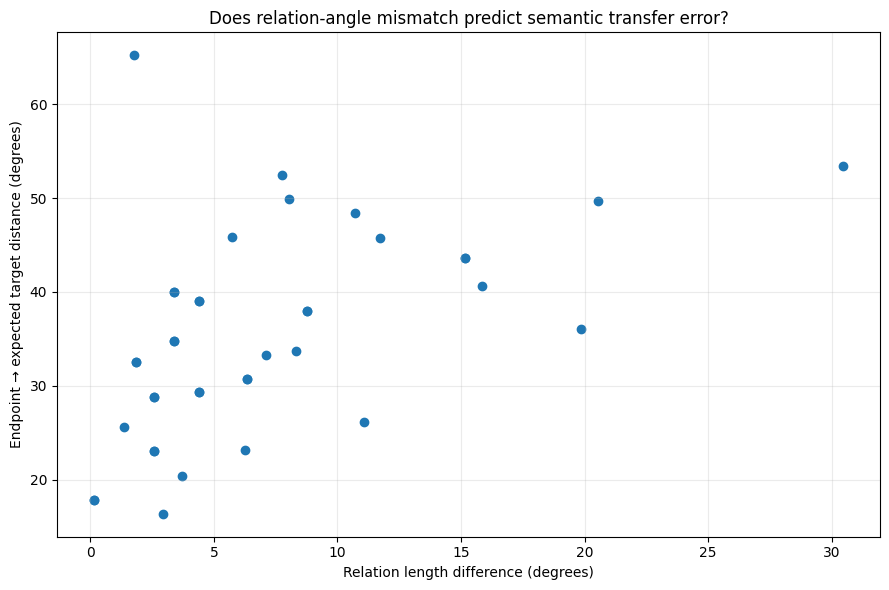

In [26]:
import numpy as np
import matplotlib.pyplot as plt

if len(transport_df) > 1:
    x = transport_df[
        "relation_length_difference_deg"
    ].to_numpy()

    y = transport_df[
        "distance_endpoint_to_target_deg"
    ].to_numpy()

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if valid.sum() >= 2:
        correlation = np.corrcoef(
            x[valid],
            y[valid],
        )[0, 1]

        print(
            "Correlation between relation-length mismatch "
            "and endpoint-target error:",
            f"{correlation:.4f}",
        )

    plt.figure(
        figsize=(9, 6)
    )

    plt.scatter(
        transport_df[
            "relation_length_difference_deg"
        ],
        transport_df[
            "distance_endpoint_to_target_deg"
        ],
    )

    plt.xlabel(
        "Relation length difference (degrees)"
    )

    plt.ylabel(
        "Endpoint → expected target distance (degrees)"
    )

    plt.title(
        "Does relation-angle mismatch predict semantic transfer error?"
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()

## 18. Nearest words after transport

这里逐个查看 transport endpoint 周围的词。

例如：

```text
man → woman
king → ?
```

如果 `queen` 在 transport endpoint 的 nearest neighbours 中排名较高，说明该 relation 在新的 base point 上保留了一部分语义。


In [28]:
for relation_name, result in transport_details.items():
    print("\n" + "=" * 70)
    print(relation_name)

    display(
        pd.DataFrame([
            result["summary"]
        ])
    )

    display(
        result["neighbors"]
    )



[gender_family] man→woman | king→queen


,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,category
0,man→woman,king→queen,23.553115,32.340914,8.787799,5.551115e-17,86.30494,32.340914,37.9759,-5.634986,7,0.78827,False,False,gender_family


,rank,word,cosine_similarity,angle_deg
0,1,regent,0.880050,28.351628
1,2,emperor,0.854374,31.309342
2,3,prince,0.853776,31.375242
3,4,empress,0.806515,36.243166
4,5,lavinia,0.803505,36.533917
5,6,count,0.799905,36.878921
6,7,queen,0.788270,37.975900
7,8,sancho,0.786554,38.135404
8,9,macedon,0.781142,38.634771
9,10,grandson,0.780621,38.682566



[gender_family] king→queen | man→woman


,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,category
0,king→queen,man→woman,32.340914,23.553115,8.787799,0.0,86.30494,23.553115,37.9759,-14.422785,1,0.78827,True,True,gender_family


...

,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,category
0,paris→france,berlin→germany,34.923603,32.360175,2.563428,1.110223e-16,41.991999,32.360175,23.026593,9.333582,1,0.920323,True,True,geography


,rank,word,cosine_similarity,angle_deg
0,1,germany,0.920323,23.026593
1,2,india,0.867366,29.845967
2,3,macedonia,0.862185,30.437242
3,4,china,0.861890,30.470583
4,5,turkey,0.850101,31.777324
5,6,flanders,0.838486,33.019412
6,7,sarajevo,0.831900,33.705639
7,8,europe,0.829831,33.918609
8,9,east,0.829118,33.991767
9,10,italy,0.826929,34.215474



[geography] tokyo→japan | beijing→china


,relation_source,transfer_test,original_relation_angle_deg,true_target_relation_angle_deg,relation_length_difference_deg,transported_norm_error,direction_error_deg,distance_c_to_target_before_deg,distance_endpoint_to_target_deg,distance_improvement_deg,target_rank,target_cosine_similarity,top1_correct,top5_correct,category
0,tokyo→japan,beijing→china,47.315762,42.910707,4.405055,0.0,41.481884,42.910707,29.366191,13.544516,1,0.871503,True,True,geography


,rank,word,cosine_similarity,angle_deg
0,1,china,0.871503,29.366191
1,2,europe,0.857117,31.005613
2,3,taiwan,0.824650,34.446929
3,4,brazil,0.823236,34.589977
4,5,asia,0.821734,34.741287
5,6,abkhazia,0.815166,35.396196
6,7,argentina,0.812104,35.697990
7,8,belgium,0.810519,35.853319
8,9,africa,0.806710,36.224309
9,10,india,0.803461,36.538121
